# 04 · Pregunta 2b: afinidades entre géneros

**Responsable:** Integrante D · **Plan:** ver `PLAN.md`

¿Qué géneros tienden a gustar juntos, más allá de que se asignen juntos a las mismas películas?

## Preparación

In [155]:
import importlib

importlib.reload(afinidades_generos)
importlib.reload(contratos)

<module 'src.contratos' from 'c:\\Users\\chiva\\OneDrive\\Documentos\\DIPLOMADO METODOS\\Modulo 1\\.vscode\\movielens-proyecto-integrador\\src\\contratos.py'>

In [156]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Busca la raíz del repo (la carpeta que contiene src/) sin importar desde dónde se abra el notebook.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(RAIZ))


sns.set_theme(style="whitegrid")  # estilo común para todas las figuras del proyecto

from src import contratos, rutas
from src import limpieza, afinidades_generos


## Datos

In [108]:
movies, ratings = limpieza.datos_limpios()
contratos.verificar_esquema(movies, "movies")
contratos.verificar_esquema(ratings, "ratings")
print(movies.shape, ratings.shape)

(300, 23) (8492, 5)


c:\Users\chiva\OneDrive\Documentos\DIPLOMADO METODOS\Modulo 1\.vscode\movielens-proyecto-integrador\src\limpieza.py:66: UserWarning: cargar_movies() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
c:\Users\chiva\OneDrive\Documentos\DIPLOMADO METODOS\Modulo 1\.vscode\movielens-proyecto-integrador\src\limpieza.py:66: UserWarning: movies_limpias() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
c:\Users\chiva\OneDrive\Documentos\DIPLOMADO METODOS\Modulo 1\.vscode\movielens-proyecto-integrador\src\limpieza.py:66: UserWarning: cargar_ratings() es un DUMMY: devuelve datos inventados con el esquema del contrato.
  return movies_limpias(cargar_movies()), ratings_limpias(cargar_ratings())
c:\Users\chiva\OneDrive\Documentos\DIPLOMADO METODOS\Modulo 1\.vscode\movielens-proyecto-integrador\src\limpieza.py:66:

## 1. Panorama por género

In [109]:
# TODO: tabla por género: n de películas, n de ratings, media, mediana, std

#Agrupamos ratings por movieId y calculamos el número de ratings y la media de los ratings por película
rating_por_pelicula=ratings.groupby('movieId').agg(n_ratings=("rating", "count"), media_rating=("rating", "mean")).reset_index()

#obtenemos la lista de géneros únicos en el dataset de movies
print(movies.columns.tolist())
col_gen=['Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']

#hacemos el cruce de tablas
tabla_completa=pd.merge(movies[['movieId']+col_gen], rating_por_pelicula, on='movieId', how='left')

#usamos melt para convertir las columnas de géneros en filas
tabla_conv=tabla_completa.melt(
    id_vars=['movieId' ,'n_ratings','media_rating'],
    value_vars=col_gen,
    var_name='genres',
    value_name='has_genre'
)

#Nos quedamos solo la s filas donde has_genre es 1 (es decir, la película pertenece a ese género)
tabla_conv=tabla_conv[tabla_conv['has_genre']==1]

#obtenemos la tabla resumen por género
tabla_resumen=tabla_conv.groupby('genres').agg(n_peliculas=("movieId", "count"),n_ratingsT=("n_ratings", "sum"),mean_rating=("media_rating", "mean"),median_rating=("media_rating", "median"), std_rating=("media_rating", "std") ).reset_index()
print(tabla_resumen)

['movieId', 'title', 'anio', 'n_generos', 'es_imax', 'Action', 'Adventure', 'Animation', 'Children', 'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir', 'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War', 'Western']
         genres  n_peliculas  n_ratingsT  mean_rating  median_rating  \
0        Action           38      1333.0     3.470022       3.406593   
1     Adventure           37       997.0     3.411344       3.470114   
2     Animation           41      1021.0     3.500001       3.500000   
3      Children           40      1105.0     3.459806       3.517857   
4        Comedy           37       794.0     3.529445       3.500000   
5         Crime           38      1043.0     3.435639       3.493421   
6   Documentary           43      1126.0     3.565527       3.536585   
7         Drama           38      1174.0     3.509609       3.500000   
8       Fantasy           35       777.0     3.443218       3.417411   
9     Film-Noir           42 

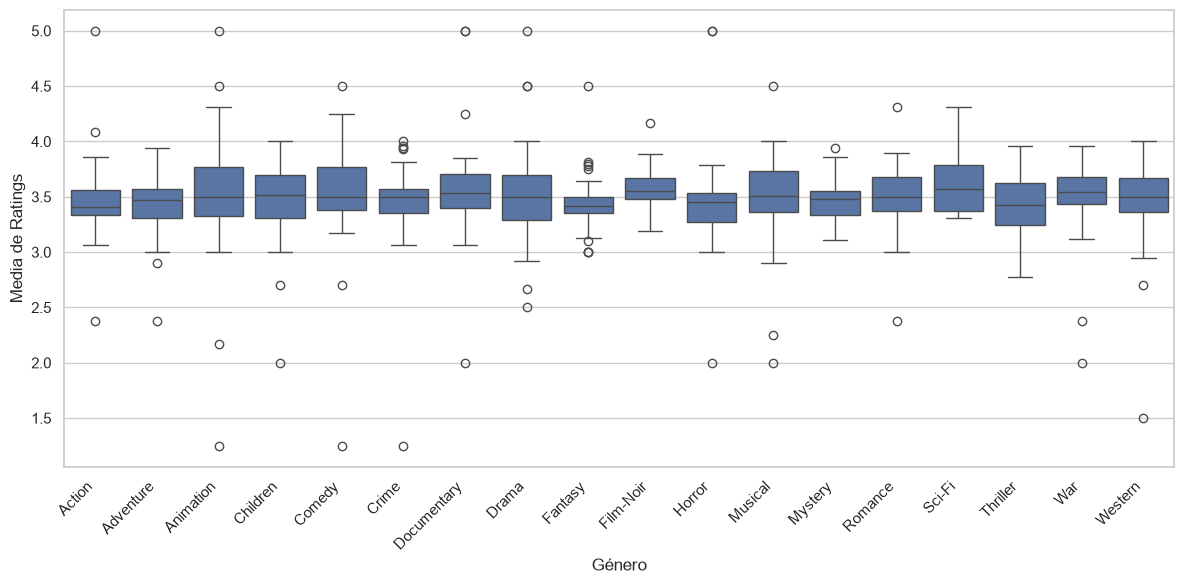

In [110]:
# TODO: boxplot de ratings por género (sns.boxplot necesita formato largo: una fila por rating y género)
# rutas.guardar_figura(fig, "04_boxplot_generos")
plt.figure(figsize=(12, 6))
sns.boxplot(x='genres', y='media_rating', data=tabla_conv)

plt.xlabel('Género', fontsize=12)
plt.ylabel('Media de Ratings', fontsize=12)
plt.xticks(rotation=45,ha='right')
plt.tight_layout()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 2. Coocurrencia de géneros

Correlación entre las 18 columnas 0/1 de `movies`.

             Action  Adventure  Animation  Children  Comedy  Crime  \
Action         1.00      -0.05       0.11      0.03    0.04  -0.05   
Adventure     -0.05       1.00      -0.03      0.00    0.01  -0.08   
Animation      0.11      -0.03       1.00     -0.07    0.15  -0.03   
Children       0.03       0.00      -0.07      1.00    0.00   0.06   
Comedy         0.04       0.01       0.15      0.00    1.00   0.07   
Crime         -0.05      -0.08      -0.03      0.06    0.07   1.00   
Documentary    0.02      -0.01       0.00     -0.05    0.16  -0.01   
Drama          0.16      -0.02      -0.03     -0.00    0.01  -0.08   
Fantasy       -0.01       0.05       0.01     -0.08   -0.04  -0.01   
Film-Noir      0.14      -0.01      -0.08      0.01   -0.01  -0.04   
Horror         0.15       0.05      -0.03      0.00   -0.12  -0.02   
Musical        0.09      -0.00      -0.02      0.05   -0.00  -0.01   
Mystery       -0.03      -0.03      -0.07     -0.01   -0.03   0.03   
Romance       -0.03 

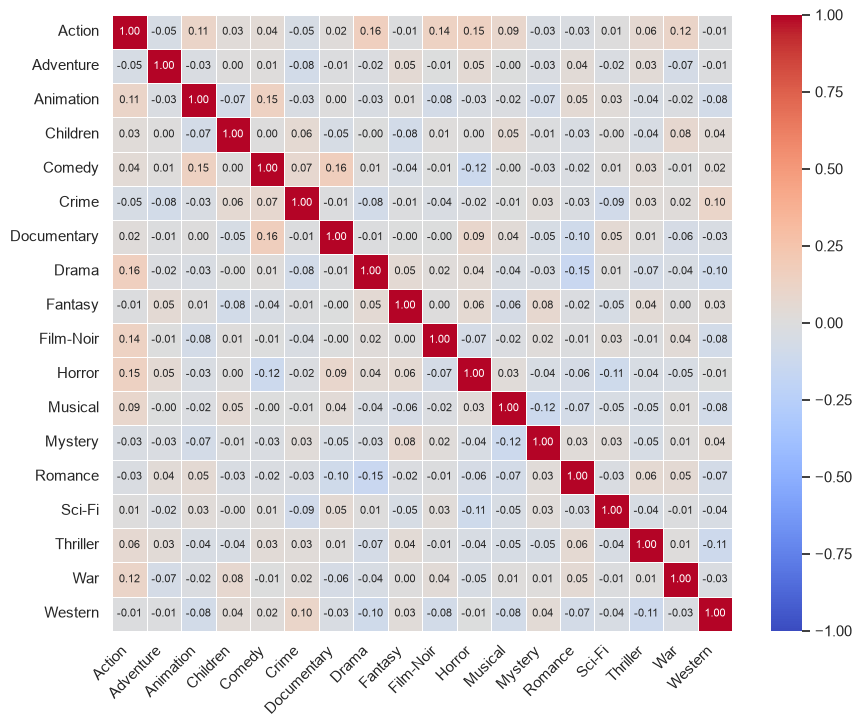

In [111]:
# TODO: matriz de correlación de coocurrencia
matriz_corr=movies[col_gen].corr()
print(matriz_corr.round(2))
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr, annot=True, annot_kws={'size': 8}, fmt='.2f', cmap='coolwarm',vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

## 3. Preferencias por género

In [159]:
perfil = afinidades_generos.perfil_genero(ratings, movies, min_r=5)
contratos.verificar_matriz(perfil, "proporcion", contratos.GENEROS)
perfil.shape

(120, 18)

             Action  Adventure  Animation  Children  Comedy  Crime  \
Action         1.00       0.11      -0.01     -0.01    0.19  -0.01   
Adventure      0.11       1.00       0.16      0.36    0.28  -0.05   
Animation     -0.01       0.16       1.00      0.14    0.02   0.06   
Children      -0.01       0.36       0.14      1.00    0.05   0.21   
Comedy         0.19       0.28       0.02      0.05    1.00   0.10   
Crime         -0.01      -0.05       0.06      0.21    0.10   1.00   
Documentary    0.09       0.23      -0.01      0.17    0.35   0.07   
Drama          0.48       0.22      -0.01      0.11    0.16   0.08   
Fantasy        0.26       0.02      -0.07     -0.04    0.06  -0.15   
Film-Noir      0.02      -0.01      -0.06      0.10    0.20   0.23   
Horror         0.28       0.06      -0.06      0.21   -0.18   0.05   
Musical        0.25       0.16       0.17      0.20    0.10   0.34   
Mystery        0.05       0.06      -0.00      0.07   -0.16  -0.18   
Romance        0.03 

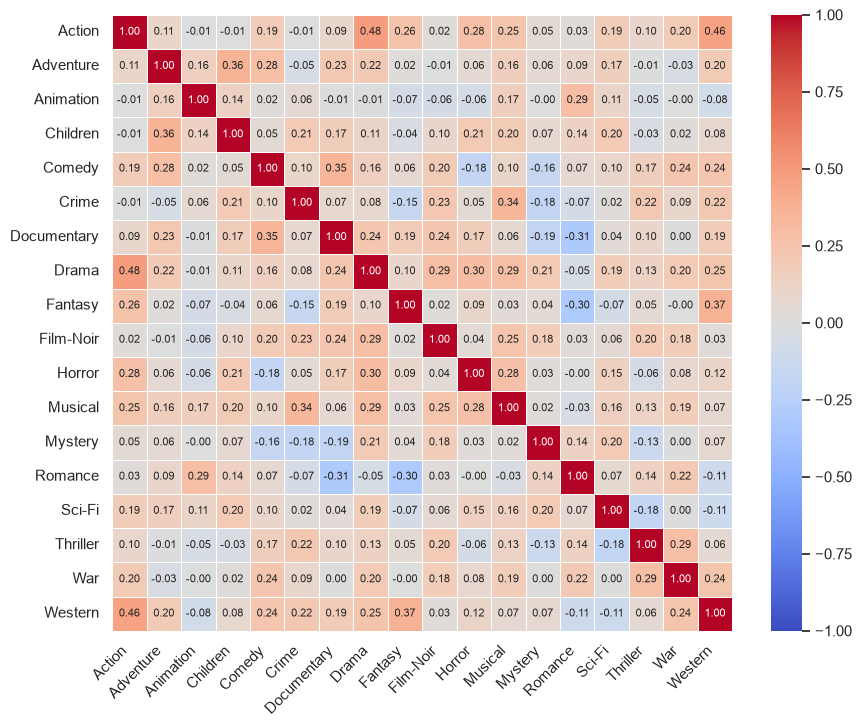

In [162]:
# TODO: matriz de correlación de preferencias (min_periods)
matriz_corr_pref = perfil.corr(min_periods=30)
print(matriz_corr_pref.round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(matriz_corr_pref, annot=True, annot_kws={'size': 8}, fmt='.2f', cmap='coolwarm',vmin=-1, vmax=1, center=0, linewidths=0.5)
plt.xticks(rotation=45, ha='right')
plt.show()

## 4. Preferencia vs. coocurrencia

C:\Users\chiva\AppData\Local\Temp\ipykernel_20884\2318881499.py:42: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


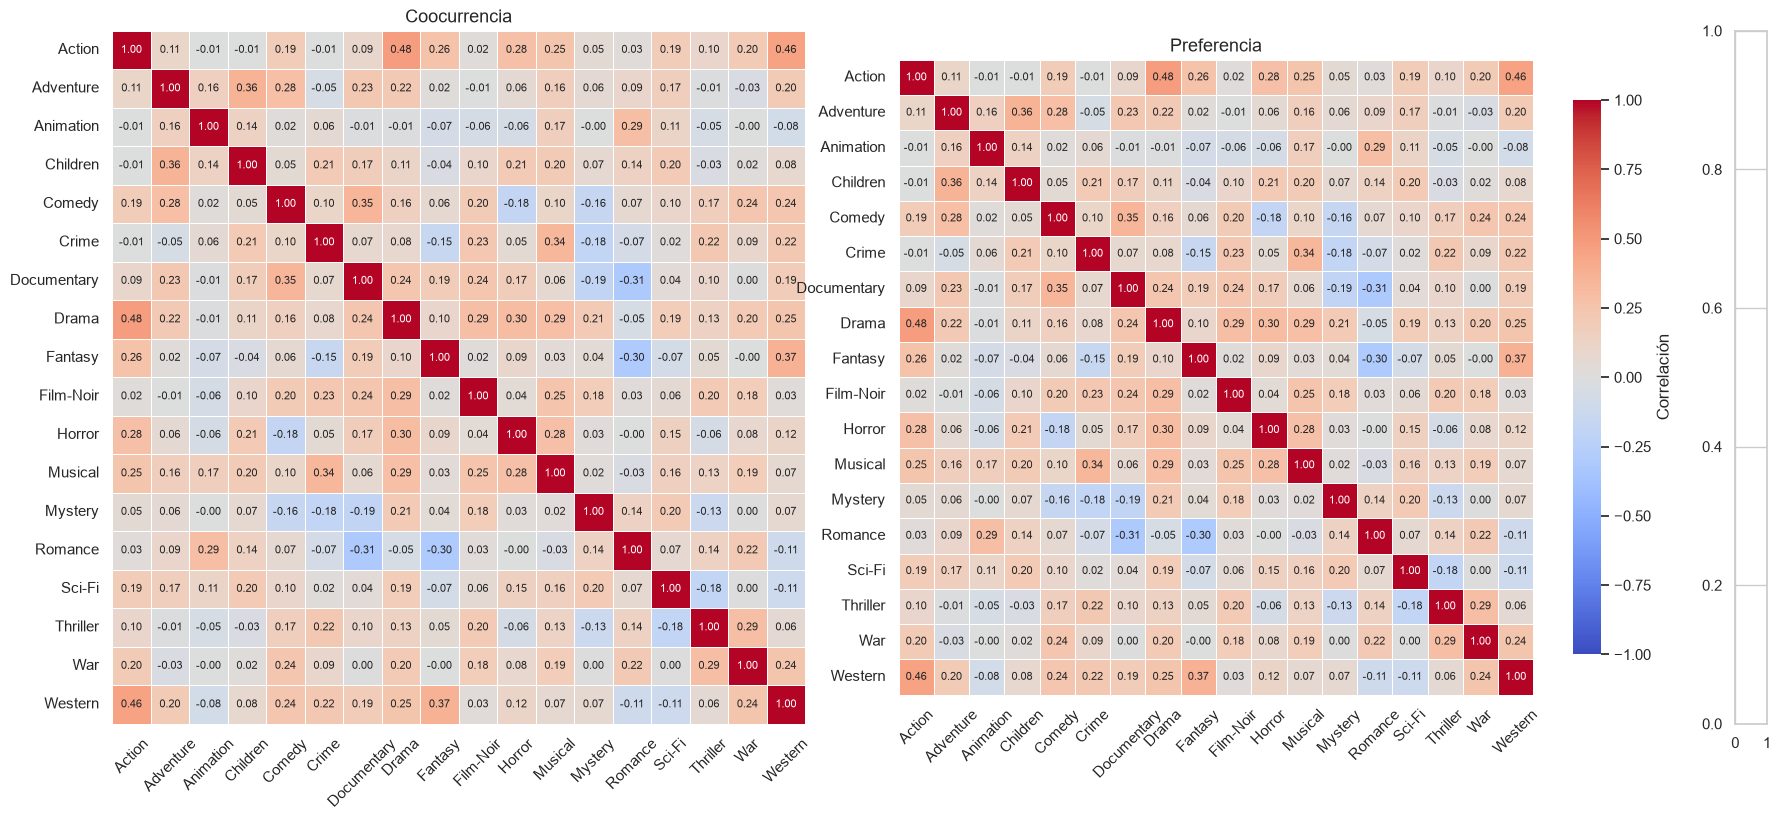

In [171]:
# TODO: los dos heatmaps lado a lado: plt.subplots(1, 2) y sns.heatmap(..., ax=ax) con la misma escala (vmin, vmax)
# rutas.guardar_figura(fig, "04_heatmaps_generos")
vmin, vmax = -1.0, 1.0
fig, (ax1, ax2, cbar_ax) = plt.subplots(1,3,figsize=(22, 9),gridspec_kw={"width_ratios": [1, 1, 0.04], "wspace": 0.08},)
sns.heatmap(
    matriz_corr,
    ax=ax1,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    center=0,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    cbar=False,  
)
ax1.set_title("Coocurrencia", fontsize=13)
ax1.tick_params(axis="x", rotation=45)
ax1.tick_params(axis="y", rotation=0)

# --- Heatmap Derecho (axes) ---
sns.heatmap(
    matriz_corr_pref,
    ax=ax2,
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    center=0,
    square=True,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.5,
    cbar=cbar_ax,
    cbar_kws={"label": "Correlación", "shrink": 0.8},
)
ax2.set_title("Preferencia", fontsize=13)
ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()

rutas.guardar_figura(fig, "04_heatmaps_generos")
plt.show()

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

In [ ]:
# TODO: scatter de los 153 pares: x = coocurrencia, y = preferencia
# rutas.guardar_figura(fig, "04_scatter_pares")

> **Interpretación**
> - *Qué muestra:* …
> - *Por qué es relevante:* …
> - *Limitaciones:* …

## 5. Conclusión y limitaciones

…